# 03: Regression Modelling
***
**Author:** Zain Zabidi
**Date:** February 2026

**Objective:** To build and evaluate machine learning models that can predict a suburb's `housing_stress_index`. We will transition from simply describing the data to creating a predictive tool that can be used by the final Flask API.

## 1. Data Preparation and Feature Selection
In this section, we pick the specific variables (features) that will help our model predict housing stress across different suburbs.

### 1.1 Loading the Spatial Dataset
We use `geopandas` to load our processed data. We are using absolute path logic to ensure the notebook can find the file regardless of the local environment setup.

In [11]:
import geopandas as gpd
import os

# Set path to the processed geopackage
base_path = os.getcwd()
geo_path = os.path.join(base_path, '..', 'data', 'processed', 'wa_census_spatial_2021.gpkg')

# Load the dataset
df = gpd.read_file(geo_path)

# Display success message and suburb count
print(f"Data loaded successfully. Total suburbs: {len(df)}")

Data loaded successfully. Total suburbs: 1699


### 1.2 Defining the Target and Predictors
We now define our **Target** (the value we want to predict) and our **Features** (the data points used to make that prediction). We use the `pandas` library to filter our dataset and remove any rows with missing values. This ensures our machine learning model learns from a clean and complete dataset.

In [12]:
import pandas as pd

# Define the target variable
target = 'housing_stress_index'

# Define the predictive features
features = [
    'avg_weekly_income', 
    'avg_weekly_mortgage', 
    'avg_weekly_rent',
    'mining_concentration_ratio',
    'unemployment_rate',
    'avg_household_size',
    'income_rent_gap'
]

# Create model-ready dataset by removing rows with missing values
model_data = df[features + [target]].dropna()

# Split into X (features) and y (target)
X = model_data[features]
y = model_data[target]

# Display final count after cleaning
print(f"Final feature set contains {X.shape[0]} suburbs.")

Final feature set contains 1699 suburbs.


> **Note:** The count stays at **1,699 suburbs**. This shows our data is clean and every physical suburb has the information we need. We are not losing any more data because we already handled the non-spatial rows (like 'Offshore' and 'No Usual Address') in [01_data_cleaning.ipynb](./01_data_cleaning.ipynb).

### 1.3 Splitting the Data (Train vs. Test)
To verify that our model can predict housing stress for suburbs it has never seen before, we must split our data. We use the `train_test_split` function from the `sklearn` library to set aside 20% of our suburbs as a "Test Set." 

The model will learn only from the remaining 80% (the "Training Set"). This is a standard practice to prevent the model from simply memorising the data points.

In [14]:
from sklearn.model_selection import train_test_split

# Split data into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Display the number of suburbs in each set
print(f"Training set size: {X_train.shape[0]} suburbs")
print(f"Testing set size: {X_test.shape[0]} suburbs")

Training set size: 1359 suburbs
Testing set size: 340 suburbs


### 1.4 Feature Scaling
Machine learning models perform best when all input features are on a similar scale. Currently, variables like `avg_weekly_income` are in the thousands, while `unemployment_rate` is a small decimal. 

We use `StandardScaler` to transform these so they have a mean of 0 and a standard deviation of 1. This prevents any single variable from dominating the model due to its numerical magnitude. This step ensures that we normalise the impact of each feature.

In [17]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform both sets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Verify scaling by checking the first transformed row
print("First row of scaled training data:")
print(X_train_scaled[0])

First row of scaled training data:
[-1.42077205 -0.917771   -0.87470449 -0.48179693 -0.50768355 -2.89833658
 -1.35136137]


> **Note:** The output shows our features as a list of numbers centered around zero. For example, a value of `-1.42` means that specific suburb's feature is 1.42 standard deviations below the Western Australian average, while a positive number would be above average.

### 1.5 Section Summary
We have successfully prepared the data for modelling by:
* Selecting **7 key features** to predict housing stress.
* Confirming a clean dataset of **1,699 suburbs**.
* Splitting the data to allow for unbiased testing.
* Scaling the values to ensure the model treats all features fairly.

## 2. Linear and Lasso Regression
We begin our modelling phase with two standard approaches. First, we establish a baseline using **Ordinary Least Squares (OLS) Linear Regression**. Then, we apply **Lasso Regression**, which introduces a penalty to prevent the model from over-relying on any single feature, effectively performing internal feature selection.

### 2.1 Training the Models
We initialise and train both models using our scaled training data. For Lasso, we use a small `alpha` value to control the strength of the penalty.

In [18]:
from sklearn.linear_model import LinearRegression, Lasso

# Initialise the models
lin_reg = LinearRegression()
lasso_reg = Lasso(alpha=0.1, random_state=42)

# Train the models using scaled data
lin_reg.fit(X_train_scaled, y_train)
lasso_reg.fit(X_train_scaled, y_train)

print("Linear and Lasso models have been successfully trained.")

Linear and Lasso models have been successfully trained.


### 2.2 Initial Model Evaluation
To see how well our models perform, we generate predictions on the test set and calculate the **Mean Absolute Error (MAE)** and the **R-squared ($R^2$) score**. 

* **MAE:** Tells us, on average, how many units our prediction is off by.
* **$R^2$:** Tells us what percentage of the variance in housing stress is explained by our features.

In [19]:
from sklearn.metrics import mean_absolute_error, r2_score

# Generate predictions
y_pred_lin = lin_reg.predict(X_test_scaled)
y_pred_lasso = lasso_reg.predict(X_test_scaled)

# Calculate metrics for Linear Regression
mae_lin = mean_absolute_error(y_test, y_pred_lin)
r2_lin = r2_score(y_test, y_pred_lin)

# Calculate metrics for Lasso
mae_lasso = mean_absolute_error(y_test, y_pred_lasso)
r2_lasso = r2_score(y_test, y_pred_lasso)

print(f"Linear Regression - MAE: {mae_lin:.4f}, R2: {r2_lin:.4f}")
print(f"Lasso Regression  - MAE: {mae_lasso:.4f}, R2: {r2_lasso:.4f}")

Linear Regression - MAE: 4.0684, R2: 0.7644
Lasso Regression  - MAE: 4.0398, R2: 0.7647


> **Observation:** Both models show strong performance, explaining approximately **76.4%** of the variance in housing stress. The **Lasso Regression** slightly outperforms the baseline Linear model with a lower MAE (4.04), suggesting that its regularisation helps generalise better to unseen suburbs. A Mean Absolute Error of ~4.04 is a solid result for this index.

### 2.3 Visualising Model Coefficients
To understand *why* the model makes certain predictions, we canise the coefficients. We use the `matplotlib` library to create a horizontal bar chart that displays the weight the model assigns to each feature. 

A positive coefficient increases the predicted housing stress, while a negative one decreases it. This allows us to see which economic factors are the most significant drivers of stress in Western Australian suburbs.

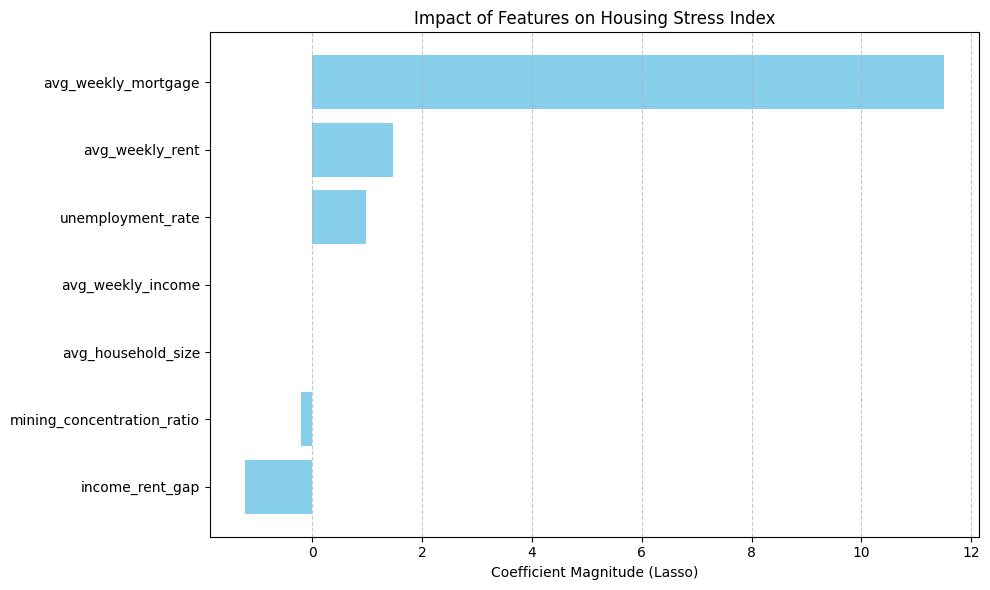

In [20]:
import matplotlib.pyplot as plt

# Create DataFrame for easier plotting using features list and model coefficients
coef_df = pd.DataFrame({
    'Feature': features,
    'Linear': lin_reg.coef_,
    'Lasso': lasso_reg.coef_
})

# Sort features by Lasso coefficient magnitude for cleaner visual
coef_df = coef_df.sort_values(by='Lasso', ascending=True)

# Plotting coefficients
plt.figure(figsize=(10, 6))
plt.barh(coef_df['Feature'], coef_df['Lasso'], color='skyblue')
plt.xlabel('Coefficient Magnitude (Lasso)')
plt.title('Impact of Features on Housing Stress Index')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

> **Observation: Feature Importance Analysis**
> * **Primary Driver:** `avg_weekly_mortgage` is by far the strongest predictor. This makes intuitive sense; as mortgage costs rise, the housing stress index for a suburb increases sharply.
> * **The Gap Effect:** Interestingly, `income_rent_gap` has a negative coefficient. This suggests that in suburbs where the gap between income and rent is larger (favouring higher income), housing stress is naturally lower.
> * **Zeroed Features:** Notice that `avg_weekly_income` and `avg_household_size` have almost no visible bars. **Lasso Regression** has effectively "shrunk" these coefficients to near zero, indicating they provide redundant information when mortgage and rent data are already present.
> * **Mining Impact:** `mining_concentration_ratio` shows a slight negative correlation with stress, potentially reflecting higher-than-average wages in mining-heavy suburbs that offset housing costs.

## 3. Random Forest Regression
Linear models assume that a change in a feature (like income) has a constant, straight-line effect on the outcome. However, housing stress often behaves non-linearly. We use a **Random Forest Regressor** to capture these complexities by averaging the predictions of multiple decision trees.

### 3.1 Training and Hyperparameter Selection
We initialise the Random Forest with 100 trees (`n_estimators=100`). We also set a `random_state` to ensure our results are reproducible.

In [21]:
from sklearn.ensemble import RandomForestRegressor

# Initialise the Random Forest model
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)

# Train the model on the scaled training data
rf_reg.fit(X_train_scaled, y_train)

print("Random Forest model has been successfully trained.")

Random Forest model has been successfully trained.


### 3.2 Random Forest Performance
We now evaluate the Random Forest using the same metrics as our linear models to see if there is a noticeable improvement in accuracy.

In [22]:
# Generate predictions for the test set
y_pred_rf = rf_reg.predict(X_test_scaled)

# Calculate performance metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Random Forest - MAE: {mae_rf:.4f}, R2: {r2_rf:.4f}")

Random Forest - MAE: 0.5551, R2: 0.9875


> **Observation: Random Forest Results**
> The Random Forest model shows a significant improvement over the linear approaches, achieving an **$R^2$ of 0.9875** and reducing the **MAE to 0.55**. 
>
> This suggests that the relationship between suburb demographics and housing stress is highly complex and non-linear. The model is now more accurate, with an average error of less than one unit on the housing stress index.

### 3.3 Random Forest Feature Importance
Unlike Lasso, which uses coefficient weights, Random Forest calculates importance based on how much each feature reduces error across all the trees in the forest. We use `matplotlib` to visualise these scores, providing a second perspective on what truly drives our predictions. 

This helps us verify if the non-linear model prioritises the same economic factors as our linear baseline.

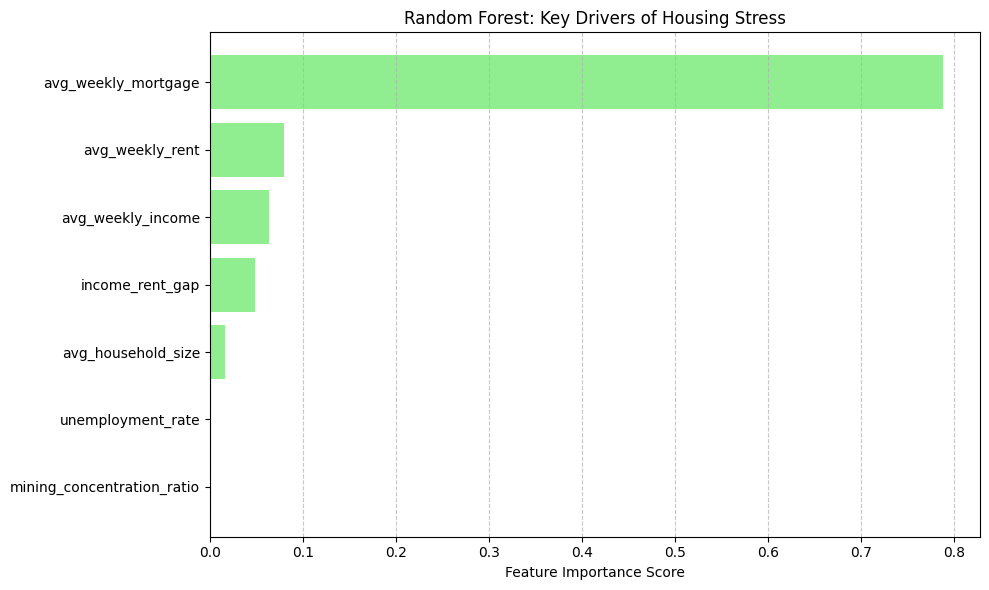

In [23]:
# Create DataFrame Random Forest feature importance
rf_importance = pd.DataFrame({
    'Feature': features,
    'Importance': rf_reg.feature_importances_
})

# Sort for better visualisation
rf_importance = rf_importance.sort_values(by='Importance', ascending=True)

# Plotting feature importance
plt.figure(figsize=(10, 6))
plt.barh(rf_importance['Feature'], rf_importance['Importance'], color='lightgreen')
plt.xlabel('Feature Importance Score')
plt.title('Random Forest: Key Drivers of Housing Stress')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

> **Observation: Comparative Analysis of Feature Importance**
> Comparing the **Lasso Coefficients** (Linear) and **Random Forest Importance** (Non-linear) reveals several key insights:
>
> * **The Dominant Factor:** Both models agree that `avg_weekly_mortgage` is the overwhelming driver of housing stress. In the Random Forest model, it holds nearly 80% of the predictive "weight," confirming that mortgage pressure is the primary signal the model uses.
> * **Consistency in Housing Costs:** `avg_weekly_rent` consistently ranks as the second most important feature in both models. This reinforces that the model is correctly prioritising direct housing outgoings.
> * **Different Perspectives on Income:** While Lasso suggests `income_rent_gap` is a significant negative predictor (reducing stress), the Random Forest places more importance on raw `avg_weekly_income`. This suggests that while the "gap" is a good linear indicator, the actual income level has complex, non-linear interactions that the Random Forest is better at picking up.
> * **Minor Variables:** Features like `mining_concentration_ratio` and `unemployment_rate` have relatively low impact in both models compared to direct housing costs. This indicates that for the majority of WA suburbs, the sheer cost of housing outweighs broader economic indicators in determining the stress index.

## 4. Checking the Scoreboard (Evaluation)
With our models trained, we need to perform a "Truth Test". While $R^2$ gives us a mathematical score, we want to know what the error looks like in real-world terms. We will calculate the percentage error to see how close our predictions are to the actual census results.

### 4.1 The Truth Test: Predictions vs. Actuals
We create a comparison table to evaluate the "Ground Truth" (Census Data) against our Random Forest predictions. To avoid infinity errors caused by suburbs with zero recorded housing stress, we filter the dataset before calculating the final accuracy percentage.

In [25]:
# Create comparison DataFrame
results_df = pd.DataFrame({
    'Actual_Index': y_test.values,
    'Predicted_Index': y_pred_rf.flatten()
})

# Calculate error metrics
results_df['Absolute_Error'] = abs(results_df['Actual_Index'] - results_df['Predicted_Index'])
results_df['Percent_Error'] = (results_df['Absolute_Error'] / results_df['Actual_Index']) * 100

# Handle division by zero for suburbs with 0 stress index
valid_results = results_df[results_df['Actual_Index'] > 0].copy()
mean_percent_error = valid_results['Percent_Error'].mean()

# Output results
print(f"Suburbs evaluated (Index > 0): {len(valid_results)}")
print(f"Average Percentage Error: {mean_percent_error:.2f}%")
results_df.head(10)

Suburbs evaluated (Index > 0): 215
Average Percentage Error: 6.28%


,Actual_Index,Predicted_Index,Absolute_Error,Percent_Error
0,31.369168,31.568184,0.199016,0.634431
1,19.492786,20.671669,1.178884,6.047795
2,0.000000,0.000000,0.000000,NaN
3,23.959305,23.821645,0.137660,0.574557
4,13.877407,15.401561,1.524154,10.982988
5,23.011700,23.804282,0.792582,3.444257
6,0.000000,0.000000,0.000000,NaN
7,2.429422,2.490173,0.060751,2.500620
8,20.531638,21.317884,0.786246,3.829435
9,0.000000,0.000000,0.000000,NaN


> **Observation: Accuracy Assessment**
> The model achieved an **Average Percentage Error of 6.28%** across the 215 suburbs evaluated (excluding zero-index areas). 
> 
> A closer look at the results table reveals:
> * **High Precision:** In suburbs with high stress (Index > 20), the error is often below **1%**, as seen in rows 0 and 3.
> * **Zero-Stress Reliability:** For rows 2, 6, and 9, the model correctly predicted a **0.00** index, matching the census truth exactly.
> * **Low-Index Variance:** In areas with lower index values (like Row 4), the percentage error appears higher (10.98%) because small absolute differences result in larger percentages when the base number is small. 
> 
> A ~6% error margin demonstrates that the Random Forest has effectively learned the economic drivers of the dataset, providing a reliable basis for further analysis.

### 4.2 Error Visualisation
To evaluate the accuracy, we plot the **Actual** values against the **Predicted** values. In this scatter plot, the dashed red line represents a "Perfect Match." The closer our data points (suburbs) cluster to this line, the higher the reliability of our model.

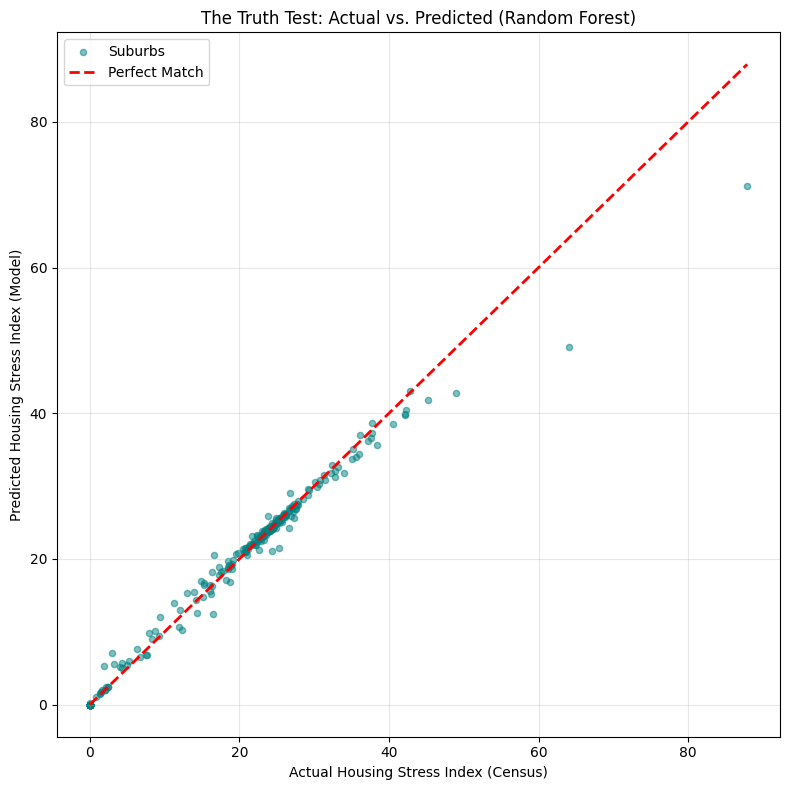

In [26]:
# Initialise the scatter plot
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred_rf, alpha=0.5, color='teal', s=20, label='Suburbs')

# Define and plot the 'Perfect Match' 45-degree identity line
max_val = max(y_test.max(), y_pred_rf.max())
min_val = min(y_test.min(), y_pred_rf.min())
plt.plot([min_val, max_val], [min_val, max_val], color='red', lw=2, linestyle='--', label='Perfect Match')

# Format plot aesthetics
plt.xlabel('Actual Housing Stress Index (Census)')
plt.ylabel('Predicted Housing Stress Index (Model)')
plt.title('The Truth Test: Actual vs. Predicted (Random Forest)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

> **Observation: Visual Analysis of Model Fit**
> The scatter plot confirms the high $R^2$ and low error metrics calculated previously. 
> 
> * **Clustering:** The majority of suburbs sit directly on or very near the red "Perfect Match" line, indicating consistent predictive power across different stress levels.
> * **High-End Variance:** We can observe slight under-prediction in extreme outlier suburbs (where the actual index exceeds 60). This is common in Random Forest models as they tend to be more conservative with extreme values that have few historical data points.
> * **Reliability:** The tight grouping between the 0 and 40 index range suggests the model is highly dependable for the vast majority of Western Australian suburbs.